# Classification de la Qualité du Vin

**EFREI Paris — ING2-BDML — 2026/2027**
**Binôme :** Awêro OKETOKOUN & *Belva*

## Objectif
Prédire si un vin est **« bon »** (note ≥ 7) ou **« pas bon »** (note < 7) à partir de ses
mesures physico-chimiques. On traite **tout le jeu de données** : vins **rouges + blancs**
réunis (jeu *Wine Quality*, UCI).

## Importation des librairies

In [ ]:
%pip install scikit-learn pandas numpy matplotlib seaborn

In [41]:
import numpy as np
np.set_printoptions(suppress=True)   # affiche les nombres sans notation scientifique
import pandas as pd
import warnings
warnings.filterwarnings('ignore')    # masque les avertissements pour un affichage propre
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Outils scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Les 5 modèles
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Métriques d'évaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)

sns.set_theme(style="whitegrid")
np.random.seed(42)
print("Librairies importées")

Librairies importées


## Chargement des données
On charge les données, et on les analyse

In [42]:
rouge = pd.read_csv('winequality-red.csv', sep=';')

rouge.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [43]:
rouge.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [44]:
rouge.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [45]:
rouge.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [46]:
blanc = pd.read_csv('winequality-white.csv', sep=';')

blanc.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [47]:
blanc.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7
4897,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6


In [48]:
blanc.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [49]:
blanc.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [50]:
# Taux de bons vins (note >= 7)
taux_rouge = (rouge['quality'] >= 7).mean()
taux_blanc = (blanc['quality'] >= 7).mean()

print(f"Rouge : {len(rouge)} vins | bons vins = {100*taux_rouge:.1f} %")
print(f"Blanc : {len(blanc)} vins | bons vins = {100*taux_blanc:.1f} %")

Rouge : 1599 vins | bons vins = 13.6 %
Blanc : 4898 vins | bons vins = 21.6 %


In [51]:
# Comparaison chimique moyenne entre rouge et blanc
colonnes_choisies = ['volatile acidity', 'residual sugar', 'total sulfur dioxide', 'alcohol']

comparaison = pd.DataFrame({
    "Rouge (moyenne)": rouge[colonnes_choisies].mean(),
    "Blanc (moyenne)": blanc[colonnes_choisies].mean(),
}).round(2)

comparaison

,Rouge (moyenne),Blanc (moyenne)
volatile acidity,0.53,0.28
residual sugar,2.54,6.39
total sulfur dioxide,46.47,138.36
alcohol,10.42,10.51


### Conclusion de l'analyse

L'analyse des deux jeux montre deux choses :

- **Un déséquilibre présent dans les deux cas** : le vin rouge compte **13,6 %** de bons
  vins (note ≥ 7) et le blanc **21,6 %**. Les deux sont déséquilibrés : réunir les fichiers
  ne crée donc pas de déséquilibre, il est déjà présent dans chaque jeu.

- **Des profils chimiques différents** : On voit que le vin blanc est plus **sucré**
  (6,39 contre 2,54 de sucre résiduel) et bien plus **soufré** (138 contre 46 de soufre
  total), tandis que le vin rouge est plus **acide** (0,53 contre 0,28 d'acidité volatile).
  Le taux d'alcool, lui parcontre, est quasi identique pour les deux (~10,5).

**Décision :** Nous décidons donc de fusionner les deux jeux pour disposer de plus de données
(6497 vins au total) tout en conservant l'information du type grâce à une
nouvelle colonne `type` (rouge / blanc). Ainsi, les modèles pourront tenir compte des
différences entre rouge et blanc. La fusion n'altèrera donc pas l'intégrité des données
(aucune valeur modifiée, aucune valeur manquante créée) — ce que nous vérifierons
juste après avec `isnull()` et `duplicated()`.

In [52]:
# On ajoute une colonne type (rouge ou blanc) pour garder l'information.
# Puis on les réunit en un seul tableau avec pd.concat
# On charge les deux fichiers
rouge = pd.read_csv('winequality-red.csv', sep=';')
blanc = pd.read_csv('winequality-white.csv', sep=';')

# On garde la trace du type de vin avant la fusion
rouge['type'] = 'rouge'
blanc['type'] = 'blanc'

# On fusionne les deux jeux en un seul
df = pd.concat([rouge, blanc], ignore_index=True)

print("Vins rouges :", len(rouge), "| Vins blancs :", len(blanc), "| Total :", len(df))

Vins rouges : 1599 | Vins blancs : 4898 | Total : 6497


## Vérification de l'intégrité des données
Regardons ce que contient le jeu de données : taille, aperçu,
types, statistiques, valeurs manquantes et doublons.


In [53]:
# Dimensions : (nombre de lignes = vins, nombre de colonnes = variables)
print("Dimensions :", df.shape)

Dimensions : (6497, 13)


In [54]:
# Affichons les 5 premières lignes du jeu de données
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,rouge
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,rouge
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,rouge
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge


In [55]:
# Affichons les 5 dernières lignes
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,blanc
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,blanc
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,blanc
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,blanc
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,blanc


In [56]:
# Détails sur le type de chaque colonne et le nombre de valeurs non nulles
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [57]:
# Statistiques descriptives (moyenne, écart-type, min, max, quartiles)
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [58]:
# Valeurs manquantes par colonne
# On vérifie s'il y a des valeurs manquantes dans le jeu de données
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())
print("\nTotal de valeurs manquantes :", df.isnull().sum().sum())

Valeurs manquantes par colonne :
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64

Total de valeurs manquantes : 0


In [59]:
# Doublons
# Nombre de lignes identiques
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 1177


In [60]:
# On supprime les 1177 doublons exacts pour éviter la fuite de données (train/test)
avant = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Doublons supprimés : {avant - len(df)}  |  Lignes restantes : {len(df)}")

Doublons supprimés : 1177  |  Lignes restantes : 5320


On ne constate donc aucune valeur manquante sur les 6497 lignes du jeu de données.
Par contre on a 1177 lignes exactement identiques (18 % du jeu), sans étiquette contradictoire.
Comme il est très improbable que 18 % de vins aient des mesures identiques par hasard, on considère que ce sont des enregistrements dupliqués. On les supprime pour éviter qu'une même ligne se retrouve à la fois dans l'entraînement et le test (fuite de données), ce qui fausserait l'évaluation.

La colonne type est catégorielle donc de type texte. Or les modèles ne comprennent que des nombres, donc on l'encode : blanc = 0 et rouge = 1. 

In [61]:
df['type'] = df['type'].map({'blanc': 0, 'rouge': 1})
df['type'].value_counts()

type
0    3961
1    1359
Name: count, dtype: int64

Ensuite on crée la cible `bon_vin` : **1 si la note ≥ 7**, sinon 0.

In [62]:
df['bon_vin'] = (df['quality'] >= 7).astype(int)
print(df[['quality', 'bon_vin']].value_counts().sort_index())

quality  bon_vin
3        0            30
4        0           206
5        0          1752
6        0          2323
7        1           856
8        1           148
9        1             5
Name: count, dtype: int64


On regarde la répartition entre bon et pas bon

Effectifs par classe : {0: 4311, 1: 1009}


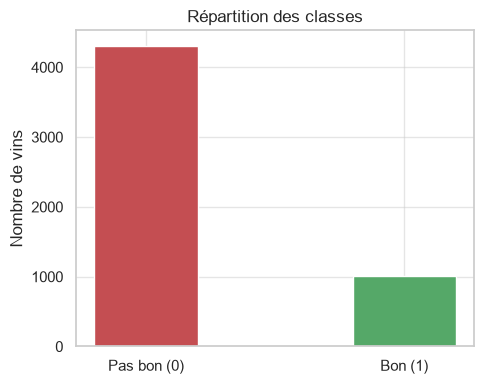

Bon : 0.190 et Pas bon : 0.810


In [63]:
histogram = Counter(df['bon_vin'])
print("Effectifs par classe :", dict(histogram))

plt.figure(figsize=(5,4))
plt.bar(histogram.keys(), histogram.values(), 0.4, color=['#c44e52', '#55a868'])
plt.xticks([0,1], ['Pas bon (0)', 'Bon (1)'])
plt.ylabel("Nombre de vins")
plt.title("Répartition des classes")
plt.tight_layout(); plt.savefig("fig_classes.png", dpi=120); plt.show()

# Proportions
bon = np.sum(df['bon_vin']==1)/len(df)
pasbon = np.sum(df['bon_vin']==0)/len(df)
print('Bon : {0:.3f} et Pas bon : {1:.3f}'.format(bon, pasbon))

Après l'analyse de la répartition des classes, on voit que le jeu est déséquilibré (~80 % de « pas bons », ~20 % de « bons »). Ce qui veut dire qu'un modèle qui dirait « pas bon » tout le temps aurait déjà ~80 % d'accuracy sans rien comprendre. L'accuracy seule est donc trompeuse : on jugera surtout avec le rappel/recall et le F1-score.

Faisons donc quelques visualisations.
Commençons par la matrice de corrélation qui nous servira de première méthode de sélection/filtre sur le choix de nos variables. Elle sert à voir quelles variables sont le plus liées à la qualité, et à repérer d'éventuelles variables redondantes entre elles.

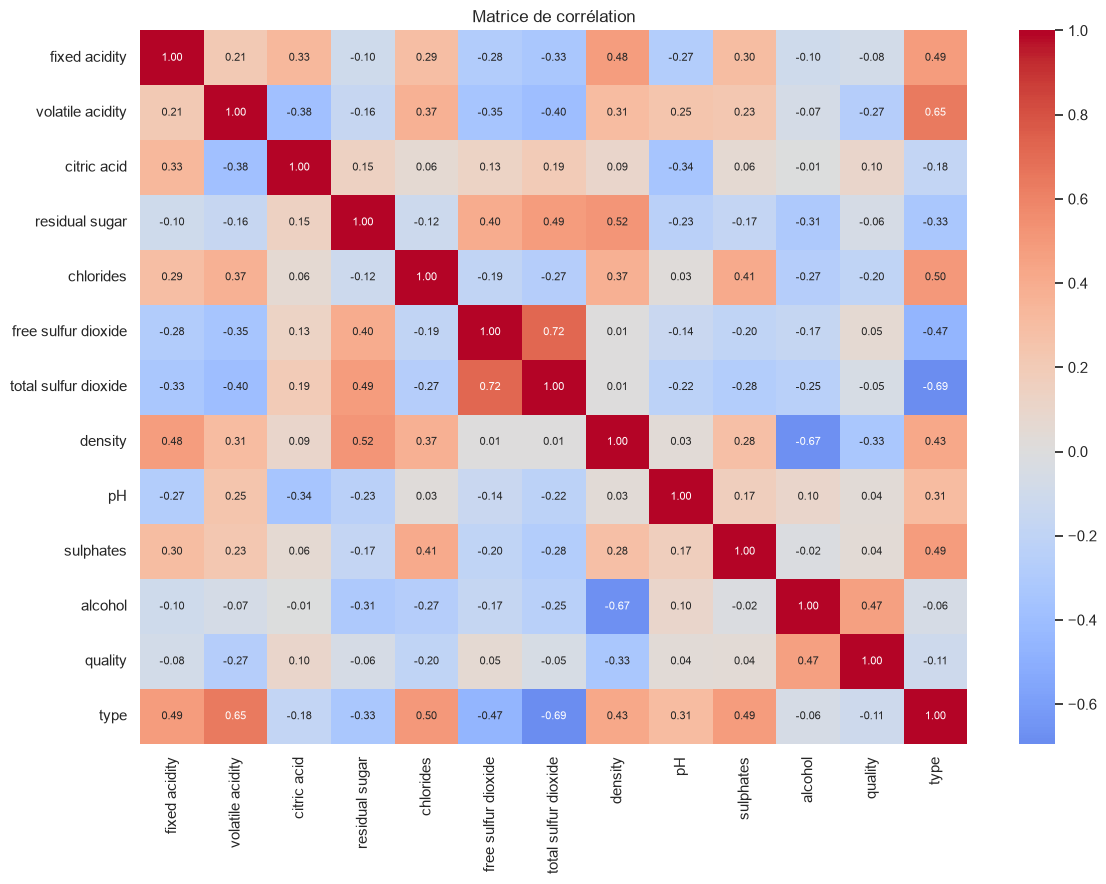

Corrélation (valeur absolue) de chaque variable avec la qualité :
alcohol                 0.469
density                 0.326
volatile acidity        0.265
chlorides               0.202
type                    0.115
citric acid             0.098
fixed acidity           0.080
residual sugar          0.057
free sulfur dioxide     0.054
total sulfur dioxide    0.050
sulphates               0.042
pH                      0.040
Name: quality, dtype: float64


In [64]:
plt.figure(figsize=(12,9))
corr = df.drop(columns=['bon_vin']).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={"size":8})
plt.title("Matrice de corrélation")
plt.tight_layout(); plt.savefig("fig_correlation.png", dpi=120); plt.show()

print("Corrélation (valeur absolue) de chaque variable avec la qualité :")
print(corr['quality'].drop('quality').abs().sort_values(ascending=False).round(3))

La variable la plus liée à la qualité est ici le **taux d'alcool**. Il y a aussi la densité (−0,33) et l'acidité volatile (−0,27). 
La matrice montre également une forte corrélation (+0,72) entre free sulfur dioxide et total sulfur dioxide, ce qui est possible puisque l'un est une composante de l'autre. 

Avec seulement 11 variables, supprimer des colonnes ne nous rapporterait rien. On a donc choisi de toutes les conserver. On confirmera leur importance avec les scores d'importance du modèle (feature_importances_ de l'arbre / Random Forest).

### Histogrammes des variables

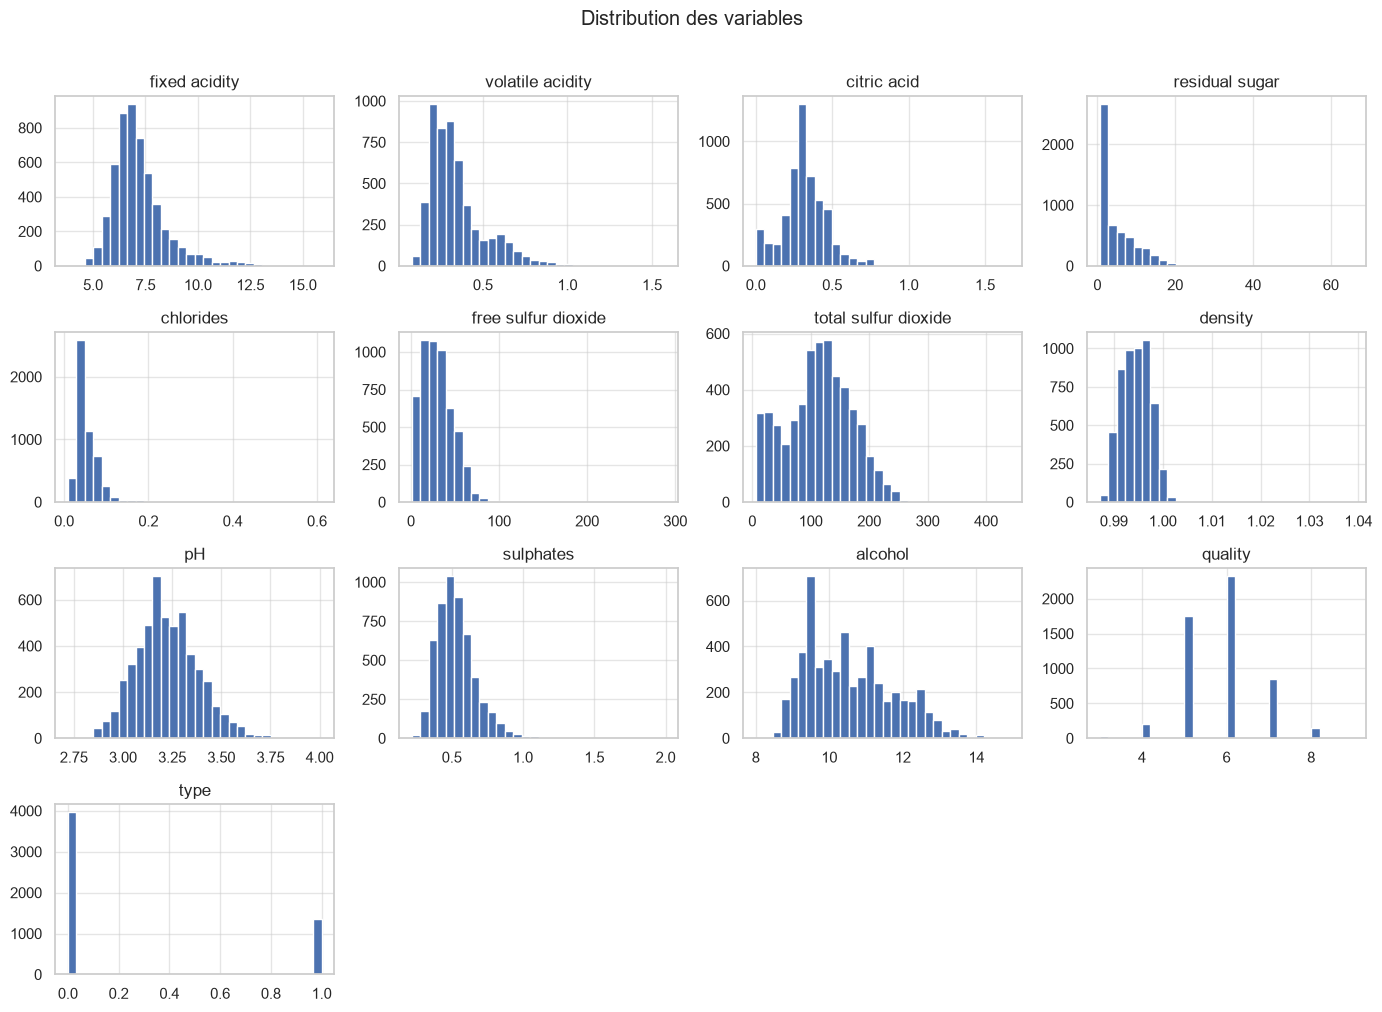

In [65]:
# On retire la colonne 'bon_vin' pour ne pas fausser les histogrammes
df.drop(columns=['bon_vin']).hist(figsize=(14,10), bins=30, color='#4c72b0')
plt.suptitle("Distribution des variables", y=1.01)
plt.tight_layout(); plt.savefig("fig_histogrammes.png", dpi=120); plt.show()

Ici l'histogramme sert à nous montrer la distribution de chaque variable, c'est à dire pour chaque tranche de valeurs, combien de vins tombent dedans. Ça permet de voir leur forme : certaines sont à peu près symétriques, d'autres très asymétriques comme le sucre résiduel. On regarde également s'il y a des valeurs extrêmes : il en existe quelques-unes (par exemple sur le sucre résiduel et les chlorures), mais on choisit de les conserver car elles peuvent correspondre à de vrais vins atypiques, pas à des erreurs ; et si les variables sont à des échelles très différentes comme par exemple le total sulfur dioxide qui monte à 140 ou encore la densité qui tourne autour de 1, ce qui justifie la standardisation. Donc au final l'analyse de la distribution des variables nous dis si on doit standardiser ou non les variables, si certaines variables violent les hypothèses d'un modèle, et où sont les cas atypiques.

On enchaîne ensuite avec les boxplots pour savoir si une variable est utile ou non pour prédire si un vin est bon ou non.

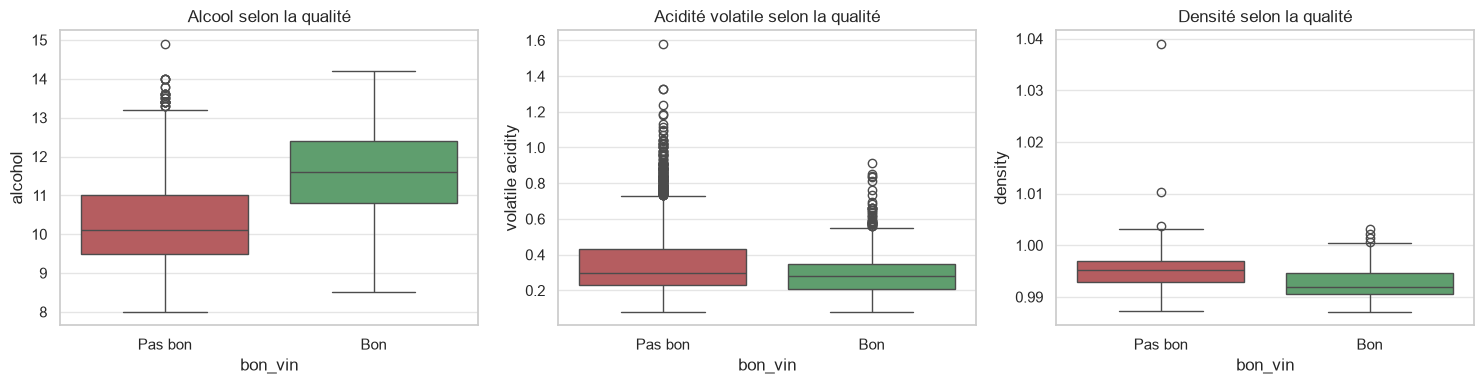

In [66]:
#Ici, on choisit de représenter les 3 variables les plus corrélées avec la qualité
fig, axes = plt.subplots(1, 3, figsize=(15,4)) #On crée une figure avec 1 ligne et 3 colonnes de dessin côte à côte pour les boxplots.
sns.boxplot(x='bon_vin', y='alcohol', data=df, ax=axes[0], palette=['#c44e52', '#55a868'])
axes[0].set_title("Alcool selon la qualité"); axes[0].set_xticklabels(['Pas bon','Bon'])
sns.boxplot(x='bon_vin', y='volatile acidity', data=df, ax=axes[1], palette=['#c44e52', '#55a868'])
axes[1].set_title("Acidité volatile selon la qualité"); axes[1].set_xticklabels(['Pas bon','Bon'])
sns.boxplot(x='bon_vin', y='density', data=df, ax=axes[2], palette=['#c44e52', '#55a868'])
axes[2].set_title("Densité selon la qualité"); axes[2].set_xticklabels(['Pas bon','Bon'])
plt.tight_layout(); plt.savefig("fig_boxplots.png", dpi=120); plt.show()

On constate que les bons vins ont un taux d'alcool nettement supérieur, une acidité
volatile plus faible, et une densité légèrement plus faible. Plus un vin est alcoolisé, moins il est dense (l'alcool est moins dense que l'eau), ce qui explique aussi la forte corrélation entre alcool et densité (−0,67).
Ces trois variables séparent visiblement les deux classes, ce qui confirme leur lien
avec la qualité.

## Préparation des données pour les modèles
### Variables (X) et cible (y)

On sépare les variables explicatives (X) de ce qu'on veut prédire (y). On retire `quality` (qui a servi à créer la cible) et `bon_vin` (la cible elle-même). On garde `type` comme variable.

In [67]:
X = df.drop(columns=['quality', 'bon_vin'])   # toutes les variables sauf quality et bon_vin
y = df['bon_vin']                               # la cible : bon (1) ou pas bon (0)
print("X :", X.shape, "| y :", y.shape)

X : (5320, 12) | y : (5320,)


### Découpage entraînement / test

On découpe ensuite pour l'entraînement et le test
On garde 75 % pour entraîner et 25 % pour tester (test_size=0.25, random_state=1, comme en TP).
`stratify=y` garde 20 % de bons vins dans le train ET dans le test, soit la même proportion de bons/pas bons dans les deux paquets.

In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

print("Entraînement :", X_train.shape[0], "vins | Test :", X_test.shape[0], "vins")

Entraînement : 3990 vins | Test : 1330 vins


### Standardisation (StandardScaler)
On met toutes les variables à la même échelle (moyenne 0, écart-type 1). Très important pour les modèles K-NN, SVM et la régression logistique.

In [69]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()                   #recentre chaque variable autour de 0 avec un écart-type de 1.
ss.fit(X_train)                         #on apprend moyenne et écart-type sur le TRAIN seulement
X_train_norm = ss.transform(X_train)   # on l'applique au train
X_test_norm = ss.transform(X_test)        # applique la même échelle au test
print("Données standardisées")

Données standardisées


## Entraînement et évaluation des modèles
On teste les 5 modèles du cours, un par un. Pour chacun : entraînement sur les données
normalisées, prédiction sur le test, puis évaluation avec la matrice de confusion et le
rapport de classification (précision, rappel, F1).

**Choix des modèles (linéaires vs non linéaires).** On compare volontairement deux familles :
- des modèles **linéaires** : régression logistique, SVM linéaire ;
- des modèles **non linéaires** : k-NN, arbre de décision, Naive Bayes, SVM à noyau RBF.

**Hypothèse.** Comme notre jeu réunit des vins rouges et blancs, chimiquement différents,
l'effet d'une variable sur la qualité peut dépendre de la couleur (interaction avec `type`).
Un modèle linéaire applique une seule règle globale et capte mal ce genre d'interaction, alors qu'un modèle non linéaire (surtout les arbres) peut adapter ses décisions selon la couleur. On s'attend donc à ce que les modèles non linéaires soient meilleurs ici, ce qu'on vérifiera avec les résultats.

Le 1er modèle : la régression logistique

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# 1. On crée le modèle
logreg = LogisticRegression(max_iter=5000, random_state=0)

# 2. On l'entraîne sur les données d'entraînement NORMALISÉES
logreg.fit(X_train_norm, y_train)

# 3. On prédit sur le test
y_logreg = logreg.predict(X_test_norm)

# 4. On évalue
print("===== Régression logistique =====")
print(confusion_matrix(y_test, y_logreg))
print(classification_report(y_test, y_logreg))

===== Régression logistique =====
[[1024   54]
 [ 189   63]]
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      1078
           1       0.54      0.25      0.34       252

    accuracy                           0.82      1330
   macro avg       0.69      0.60      0.62      1330
weighted avg       0.79      0.82      0.79      1330



On obtient 82 % d'accuracy mais seulement 0,25 de recall et 0,34 de F1 sur les bons vins (63 retrouvés sur 252). Elle reste trop influencée par la classe majoritaire. On confirme qu'il faut juger les modèles sur le recall et le F1.

Modèle 2 — k-NN

In [71]:
from sklearn.neighbors import KNeighborsClassifier

knn_3 = KNeighborsClassifier(n_neighbors=3)   # K = 3 voisins
knn_5 = KNeighborsClassifier(n_neighbors=5)   # K = 5 voisins
knn_7 = KNeighborsClassifier(n_neighbors=7)   # K = 7 voisins

knn_3.fit(X_train_norm, y_train)
knn_5.fit(X_train_norm, y_train)
knn_7.fit(X_train_norm, y_train)

y_knn_3 = knn_3.predict(X_test_norm)
y_knn_5 = knn_5.predict(X_test_norm)
y_knn_7 = knn_7.predict(X_test_norm)

In [72]:
#Analyse des performances des modèles KNN en focntion de k

print("===== k-NN (K=3) =====")
print(confusion_matrix(y_test, y_knn_3))
print(classification_report(y_test, y_knn_3))

print("===== k-NN (K=5) =====")
print(confusion_matrix(y_test, y_knn_5))
print(classification_report(y_test, y_knn_5))

print("===== k-NN (K=7) =====")
print(confusion_matrix(y_test, y_knn_7))
print(classification_report(y_test, y_knn_7))

===== k-NN (K=3) =====
[[981  97]
 [147 105]]
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      1078
           1       0.52      0.42      0.46       252

    accuracy                           0.82      1330
   macro avg       0.69      0.66      0.68      1330
weighted avg       0.80      0.82      0.81      1330

===== k-NN (K=5) =====
[[985  93]
 [138 114]]
              precision    recall  f1-score   support

           0       0.88      0.91      0.90      1078
           1       0.55      0.45      0.50       252

    accuracy                           0.83      1330
   macro avg       0.71      0.68      0.70      1330
weighted avg       0.82      0.83      0.82      1330

===== k-NN (K=7) =====
[[992  86]
 [145 107]]
              precision    recall  f1-score   support

           0       0.87      0.92      0.90      1078
           1       0.55      0.42      0.48       252

    accuracy                           0.83 

Le k-NN (k=5) atteint 83 % d'accuracy, avec un rappel de 0,45 et un F1 de 0,50 sur les bons vins (On le prendra donc comme meilleur model de k-NN) avec 114 retrouvés sur 252. C'est nettement mieux que la régression logistique (rappel 0,25) :
en regardant les 5 voisins les plus proches, ce modèle non linéaire capte des structures
locales que le modèle linéaire manquait. Premier point en faveur de notre hypothèse.

Modèle 3 — Arbre de décision

In [73]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(criterion='entropy', random_state=0)   # on choisira l'entropy comme critère de classification des features
tree.fit(X_train_norm, y_train)
y_tree = tree.predict(X_test_norm)

print("===== Arbre de décision =====")
print(confusion_matrix(y_test, y_tree))
print(classification_report(y_test, y_tree))

===== Arbre de décision =====
[[916 162]
 [143 109]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1078
           1       0.40      0.43      0.42       252

    accuracy                           0.77      1330
   macro avg       0.63      0.64      0.64      1330
weighted avg       0.78      0.77      0.77      1330



L'arbre de décision obtient 77 % d'accuracy et un F1 de 0,42 sur les bons vins (rappel 0,43,
précision 0,40). Il est non linéaire et très interprétable, mais un arbre seul a tendance à
sur-apprendre et donne des probabilités peu fiables (son AUC, 0,64, est la plus faible).
Dans ce cas, il serait envisageable d'utiliser un modèle d'ensemble comme le Random Forest, qui sort du cadre de ce projet.

Modèle 4 — Naive Bayes

In [74]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_norm, y_train)
y_nb = nb.predict(X_test_norm)

print("===== Naive Bayes =====")
print(confusion_matrix(y_test, y_nb))
print(classification_report(y_test, y_nb))

===== Naive Bayes =====
[[823 255]
 [ 86 166]]
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1078
           1       0.39      0.66      0.49       252

    accuracy                           0.74      1330
   macro avg       0.65      0.71      0.66      1330
weighted avg       0.81      0.74      0.76      1330



Naive Bayes a l'accuracy la plus faible (74 %), mais le MEILLEUR recall de tous les modèles
de base : 0,66 (166 bons vins retrouvés sur 252). En contrepartie, il déclenche beaucoup de
fausses alertes (255 faux positifs), d'où une précision basse (0,39) et un F1 de 0,49.
C'est un modèle « prudent » qui préfère ne pas rater de bons vins, au prix de plus d'erreurs.
Il suppose des variables gaussiennes et indépendantes, ce qui n'est pas tout à fait
le cas ici (d'où ses limites).

Modèle 5 — SVM

In [75]:
from sklearn.svm import SVC

svm = SVC(random_state=0)   # noyau RBF par défaut (non linéaire)
svm.fit(X_train_norm, y_train)
y_svm = svm.predict(X_test_norm)

print("===== SVM (RBF) =====")
print(confusion_matrix(y_test, y_svm))
print(classification_report(y_test, y_svm))

===== SVM (RBF) =====
[[1037   41]
 [ 186   66]]
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      1078
           1       0.62      0.26      0.37       252

    accuracy                           0.83      1330
   macro avg       0.73      0.61      0.63      1330
weighted avg       0.80      0.83      0.80      1330



Le SVM (noyau RBF) obtient la meilleure accuracy (83 %) et la meilleure précision (0,62),
mais un recall très faible (0,26, seulement 66 bons vins retrouvés). Bien qu'il soit non linéaire, il se fait piéger par le déséquilibre comme la régression logistique : par défaut, il ne tient pas compte des classes minoritaires et prédit donc rarement « bon ». Cela montre que le problème ne se résume pas à « linéaire vs non linéaire » : la gestion du déséquilibre compte tout autant.

## Comparaison des modèles
On rassemble les résultats des 5 modèles. Comme le jeu est déséquilibré, on classe par F1-score (et non par accuracy). On ajoute l'AUC et les courbes ROC.

In [76]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

# On rassemble les 5 modèles DÉJÀ entraînés
modeles = {
    "Régression logistique": logreg,
    "k-NN (K=5)": knn_5,
    "Arbre de décision": tree,
    "Naive Bayes": nb,
    "SVM (RBF)": svm,
}

lignes = []
for nom, m in modeles.items():
    pred = m.predict(X_test_norm)
    # score continu pour l'AUC : decision_function (logreg, svm) sinon predict_proba
    score = m.decision_function(X_test_norm) if hasattr(m, "decision_function") else m.predict_proba(X_test_norm)[:, 1]
    lignes.append({
        "Modèle": nom,
        "Accuracy":  accuracy_score(y_test, pred),
        "Précision": precision_score(y_test, pred),
        "Rappel":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "AUC":       roc_auc_score(y_test, score),
    })

tableau = pd.DataFrame(lignes).set_index("Modèle").sort_values("F1", ascending=False)
tableau.round(3)

,Accuracy,Précision,Rappel,F1,AUC
Modèle,,,,,
k-NN (K=5),0.826,0.551,0.452,0.497,0.796
Naive Bayes,0.744,0.394,0.659,0.493,0.765
Arbre de décision,0.771,0.402,0.433,0.417,0.641
SVM (RBF),0.829,0.617,0.262,0.368,0.812
Régression logistique,0.817,0.538,0.250,0.341,0.822


Courbes ROC

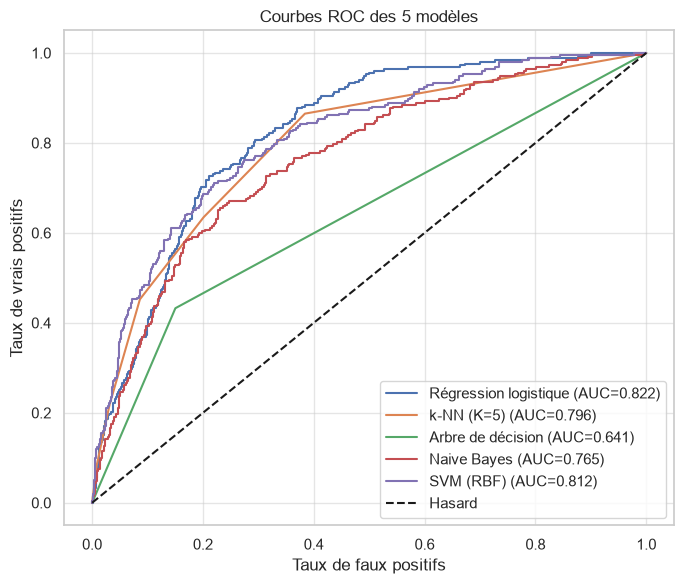

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))
for nom, m in modeles.items():
    score = m.decision_function(X_test_norm) if hasattr(m, "decision_function") else m.predict_proba(X_test_norm)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, label=f"{nom} (AUC={roc_auc_score(y_test, score):.3f})")
plt.plot([0,1], [0,1], 'k--', label="Hasard")
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs")
plt.title("Courbes ROC des 5 modèles"); plt.legend()
plt.tight_layout(); plt.savefig("fig_roc.png", dpi=120); plt.show()

### Interprétation et retour sur notre hypothèse

Classés par F1-score, les deux meilleurs modèles sont le k-NN (0,50) et Naive Bayes (0,49),
tous deux NON linéaires, tandis que la régression logistique (linéaire) ferme la marche (0,34).
Notre hypothèse est donc partiellement confirmée : les modèles non linéaires captent mieux la structure du problème que le modèle linéaire.

Mais il faut nuancer : le SVM (RBF), pourtant non linéaire, se comporte comme la régression
logistique (forte accuracy, rappel faible 0,26). La vraie clé n'est donc pas seulement « linéaire vs non linéaire », mais aussi la GESTION DU DÉSÉQUILIBRE : les modèles qui prédisent plus facilement la classe minoritaire (k-NN, Naive Bayes) obtiennent un meilleur rappel.

On observe aussi un écart entre F1 et AUC : la régression logistique et le SVM ont la meilleure AUC (~0,82), c'est-à-dire qu'ils SÉPARENT bien les classes, mais au seuil par défaut de 0,5 ils
prédisent trop peu de « bons », d'où un F1 faible. C'est exactement ce que l'optimisation va
corriger (seuil / class_weight).

En résumé : meilleur compromis global = k-NN (meilleur F1). Meilleur rappel = Naive Bayes (utile si l'objectif est de ne rater aucun bon vin).

#### Optimisation des hyperparamètres

On optimise le meilleur modèle (k-NN) avec un Grid Search (test de toutes les combinaisons d'une grille) couplé à une validation croisée k-fold (5 plis) : on découpe l'entraînement en 5 morceaux et on teste sur chacun à tour de rôle, pour un score plus fiable qu'un seul découpage.
On optimise le F1-score (notre critère). On traite ensuite le déséquilibre avec class_weight.

In [78]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Validation croisée à 5 plis, en optimisant le F1
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

grille_knn = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights":     ["uniform", "distance"],   # poids égal ou plus fort pour les voisins proches
    "metric":      ["euclidean", "manhattan"], # type de distance
}

grid_knn = GridSearchCV(KNeighborsClassifier(), grille_knn, scoring="f1", cv=cv, n_jobs=-1)
grid_knn.fit(X_train_norm, y_train)

print("Meilleurs paramètres :", grid_knn.best_params_)
print("Meilleur F1 (validation croisée) : %.3f" % grid_knn.best_score_)

# Évaluation du k-NN optimisé sur le test
y_knn_opt = grid_knn.best_estimator_.predict(X_test_norm)
print(classification_report(y_test, y_knn_opt))

Meilleurs paramètres : {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Meilleur F1 (validation croisée) : 0.514
              precision    recall  f1-score   support

           0       0.88      0.91      0.89      1078
           1       0.54      0.47      0.50       252

    accuracy                           0.82      1330
   macro avg       0.71      0.69      0.70      1330
weighted avg       0.81      0.82      0.82      1330



Le Grid Search retient metric='manhattan', K=3, weights='distance'. Le gain est modeste (F1 0,497 -> 0,501) : le k-NN était déjà bien réglé. La validation croisée confirme un F1 d'environ 0,51, cohérent avec le test — pas de sur-apprentissage.

### Traitement du déséquilibre avec class_weight
Le vrai levier contre le déséquilibre est de donner plus de poids à la classe minoritaire.
On le teste sur la régression logistique avec class_weight='balanced'.

In [79]:
logreg_bal = LogisticRegression(max_iter=5000, random_state=0, class_weight='balanced')
logreg_bal.fit(X_train_norm, y_train)
y_bal = logreg_bal.predict(X_test_norm)

print("===== Régression logistique + class_weight='balanced' =====")
print(confusion_matrix(y_test, y_bal))
print(classification_report(y_test, y_bal))

===== Régression logistique + class_weight='balanced' =====
[[768 310]
 [ 56 196]]
              precision    recall  f1-score   support

           0       0.93      0.71      0.81      1078
           1       0.39      0.78      0.52       252

    accuracy                           0.72      1330
   macro avg       0.66      0.75      0.66      1330
weighted avg       0.83      0.72      0.75      1330



Avec class_weight='balanced', la régression logistique passe d'un rappel de 0,25 à 0,78 et d'un F1 de 0,34 à 0,52 : elle retrouve désormais 196 bons vins sur 252 (contre 63 avant).
En contrepartie, la précision baisse (0,54 -> 0,39) car elle déclenche plus de fausses alertes.
C'est le compromis précision/rappel classique : selon l'objectif métier (ne pas rater un bon vin plutôt que ne jamais se tromper), on ajuste ce curseur. C'est aussi ce qui manquait au SVM, qui souffrait du même problème que la logistique de base.

### Compromis biais / variance
- Régression logistique et SVM linéaire : modèles simples, biais élevé -> ils "sous-apprennent" le problème (rappel faible).
- Arbre de décision seul : variance élevée -> il "sur-apprend" (AUC faible, 0,64, car ses probabilités sont instables).
- k-NN (bien réglé) et, en bonus, Random Forest : offrent le meilleur compromis entre les deux.
Le réglage des hyperparamètres (K pour le k-NN, class_weight pour la logistique) sert justement à déplacer ce curseur biais/variance vers le meilleur équilibre.

## Conclusion
- Jeu complet (rouge + blanc, 5320 vins après suppression des doublons), propre mais déséquilibré (~81 % de "pas bons").
- Variable la plus liée à la qualité : le taux d'alcool, suivi de la densité et de l'acidité volatile.
- Parmi les 5 modèles, les non linéaires (k-NN, Naive Bayes) obtiennent les meilleurs F1 : notre hypothèse de départ est confirmée, avec la nuance que la gestion du déséquilibre compte autant que la non-linéarité.
- Le meilleur compromis est le k-NN (F1 ~0,50) ; Naive Bayes offre le meilleur rappel brut.
- L'optimisation (Grid Search + validation croisée) affine le k-NN, et class_weight='balanced' fait bondir le rappel de la logistique (0,25 -> 0,78).

On teste le Random Forest

In [80]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf.fit(X_train_norm, y_train)
y_rf = rf.predict(X_test_norm)

print("===== Random Forest =====")
print(confusion_matrix(y_test, y_rf))
print(classification_report(y_test, y_rf))

===== Random Forest =====
[[947 131]
 [104 148]]
              precision    recall  f1-score   support

           0       0.90      0.88      0.89      1078
           1       0.53      0.59      0.56       252

    accuracy                           0.82      1330
   macro avg       0.72      0.73      0.72      1330
weighted avg       0.83      0.82      0.83      1330



Le Random Forest est un modèle d'ensemble : il combine 200 arbres de décision qui votent, ce qui corrige les erreurs d'un arbre seul. Avec class_weight='balanced' pour gérer le déséquilibre, il obtient le MEILLEUR F1 de tous nos modèles (0,56) et retrouve 148 bons vins sur 252. Cela confirme notre hypothèse : les modèles non linéaires, surtout en ensemble, sont les plus adaptés à ce jeu de données.